# LINEAR REGRESSION MODEL

## Modules

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Preprocess

In [8]:
train_df = pd.read_csv("train_1.1.csv")
test_df = pd.read_csv("test_1.1.csv")

# Convert dates, remove invalid dates, and sort rows
train_df["date"] = pd.to_datetime(train_df["date"], errors="coerce")
test_df["date"] = pd.to_datetime(test_df["date"], errors="coerce")
train_df = train_df.dropna(subset=["date"])
test_df = test_df.dropna(subset=["date"])
train_df = train_df.sort_values("date").reset_index(drop=True)
test_df = test_df.sort_values("date").reset_index(drop=True)

# Drop the raw date column
train_df = train_df.drop(columns=["date"])
test_df = test_df.drop(columns=["date"])

# Select numeric features and the target
target = "close"
features = train_df.select_dtypes(include="number").columns.tolist()
features.remove(target)

# Interpolate feature values, then remove rows still missing a feature or target
train_df[features] = train_df[features].interpolate(method="linear")
test_df[features] = test_df[features].interpolate(method="linear")
train_df = train_df.dropna(subset=features + [target])
test_df = test_df.dropna(subset=features + [target])

print("Training shape after preprocess:", train_df.shape)
print("Test shape after preprocess:", test_df.shape)

x = train_df[features].to_numpy(dtype=float)
y = train_df[target].to_numpy(dtype=float)
x_test = test_df[features].to_numpy(dtype=float)
y_test = test_df[target].to_numpy(dtype=float)
print(x)

def zscore_normalize_features(X, train_mu=None, train_sigma=None):
    if train_mu is None:
        train_mu = np.mean(X, axis=0)
    if train_sigma is None:
        train_sigma = np.std(X, axis=0)
        train_sigma[train_sigma == 0] = 1

    return (X - train_mu) / train_sigma, train_mu, train_sigma

# fit on training data only
x, train_mu, train_sigma = zscore_normalize_features(x)

# apply same training stats to test data
x_test, _, _ = zscore_normalize_features(x_test, train_mu, train_sigma)

print("Missing values in x:", np.isnan(x).sum())
print("Missing values in y:", np.isnan(y).sum())
print("Missing values in x_test:", np.isnan(x_test).sum())
print("Missing values in y_test:", np.isnan(y_test).sum())

Training shape after preprocess: (278591, 18)
Test shape after preprocess: (176220, 18)
[[ 4.55407122e+01 -1.17333467e+02 -1.19770373e+02 ... -1.21996892e+02
   2.45720000e+06 -7.63491802e+00]
 [ 3.98143740e+01  1.85981863e+02  1.69221766e+02 ... -2.83309866e+01
   2.36490000e+06  2.73919179e+02]
 [ 6.12985276e-01  1.38499549e+02  1.61580949e+02 ... -7.65244149e+01
   1.19850000e+06  8.78234532e+01]
 ...
 [-4.93615033e+01  1.94091480e+02  2.56622784e+02 ... -1.45557329e+02
   8.01300000e+05  1.78889464e+02]
 [ 5.40062352e+01  2.14019940e+01 -1.42866245e+01 ...  1.52773611e+01
   1.27940000e+06  8.22338266e+01]
 [ 7.65699865e+01  1.09004376e+00 -1.50820743e+01 ...  1.08443838e+02
   1.20450000e+06  1.97690282e+02]]
Missing values in x: 0
Missing values in y: 0
Missing values in x_test: 0
Missing values in y_test: 0


## Functions

In [9]:
def compute_loss(x,y,w,b):
    m = x.shape[0]
    error = np.dot(x, w) + b - y
    return np.sum(error ** 2) / (2 * m)

def compute_derivative(x,y,w,b):
    m = x.shape[0]
    error = np.dot(x, w) + b - y
    dj_dw = np.dot(x.T, error) / m
    dj_db = np.sum(error) / m
    return dj_dw, dj_db


def gradient_descent(x,y,w_in,b_in,learning_rate,num_iters):
    cost_history=[]
    w=w_in
    b=b_in
    for i in range(num_iters):
        dj_dw,dj_db=compute_derivative(x,y,w,b)
        w=w-learning_rate*dj_dw
        b=b-learning_rate*dj_db
        prediction=np.dot(x,w)+b
        cost=(1/(2*x.shape[0]))*np.sum(np.square(prediction-y))
        cost_history.append(cost)
        if i%100==0:
            print(f"Iteration {i}: Cost {cost}")
    return w,b,cost_history

## Model

In [10]:
w=np.zeros(x.shape[1])
b=0.0

w, b, cost_history = gradient_descent(x, y, w, b, 0.1, 8000)
print("Final cost:", cost_history[-1])


Iteration 0: Cost 2631.9863326929626


Iteration 100: Cost 88.55526762149817
Iteration 200: Cost 62.68976298043823
Iteration 300: Cost 59.77414918039357
Iteration 400: Cost 59.43374865508775
Iteration 500: Cost 59.384691789843465
Iteration 600: Cost 59.37048560960978
Iteration 700: Cost 59.36194174759881
Iteration 800: Cost 59.355434220744364
Iteration 900: Cost 59.35027352008877
Iteration 1000: Cost 59.346156518154906
Iteration 1100: Cost 59.34286907602282
Iteration 1200: Cost 59.340243455096854
Iteration 1300: Cost 59.33814616438153
Iteration 1400: Cost 59.33647071687709
Iteration 1500: Cost 59.33513212960744
Iteration 1600: Cost 59.334062569811536
Iteration 1700: Cost 59.333207887096556
Iteration 1800: Cost 59.33252484851812
Iteration 1900: Cost 59.331978933532014
Iteration 2000: Cost 59.33154257517726
Iteration 2100: Cost 59.331193756994814
Iteration 2200: Cost 59.330914893583916
Iteration 2300: Cost 59.33069193734222
Iteration 2400: Cost 59.33051366559928
Iteration 2500: Cost 59.33037111164281
Iteration 2600: Cost 59.3

## Plotting Graphs

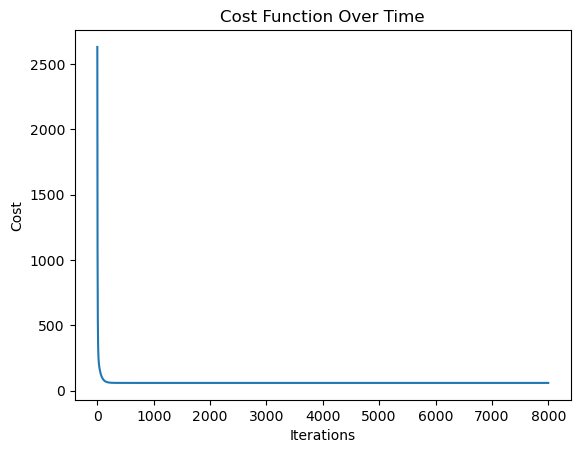

Final parameters - Bias: 64.600584277056 Weights: [ 3.62569843e+01  3.34612080e+01 -2.21419090e+01  1.61113199e+00
  8.48218095e-01  3.52462233e-02 -2.60800856e+01  3.95487665e-01
  1.20330293e+00  1.78635121e+00  4.41611207e+01  3.19980722e-02
 -2.25327600e+01  6.67384441e-01 -1.46700122e-01  4.37722292e-01]
Gradient size: 7.92496637717981e-06
Bias gradient: -6.128396983166666e-14
True
True


In [11]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function Over Time")
plt.show()
plt.close()

dj_dw, dj_db = compute_derivative(x, y, w, b)

print("Final parameters - Bias:", b, "Weights:", w)
print("Gradient size:", np.linalg.norm(dj_dw))
print("Bias gradient:", dj_db)
print(np.isclose(np.linalg.norm(dj_dw), 0, atol=1e-5))
print(np.isclose(dj_db, 0, atol=1e-5))

## Test

In [14]:
test_loss = compute_loss(x_test, y_test, w, b)

test_mse = 2 * test_loss # since the loss is given in terms of 1/2m
test_rmse = np.sqrt(test_mse)
predictions = np.dot(x_test, w) + b
ss_res = np.sum((y_test - predictions) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot)
r2_percent = r2 * 100
print("Test R-squared (Accuracy):", r2_percent, "%")


print("Test loss:", test_loss)
print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)

Test R-squared (Accuracy): 96.5014593817982 %
Test loss: 99.29610971066356
Test MSE: 198.59221942132712
Test RMSE: 14.092275168379558


## Test R-squared (Accuracy): 
0.9636728580225344

## Test loss: 
103.20205531147951

### Test MSE: 
206.40411062295902

### Test RMSE: 
14.36677105765102